# M2 MALIA - Deep Learning
## Projet HAR : Étude progressive des réseaux de neurones
### Version 1 : Baseline & Réseau à une seule couche cachée

**Auteur :** Alioune DIOP (Binôme : Madjiguène FALL)
**Enseignant :** Walid Bechkit — Université Lumière Lyon 2
**Année universitaire :** 2026–2027

---
### Objectifs de cette Version 1 :
1. Prise en main exploratoire du jeu de données HAR (Partie 1.2).
2. Découpage par volontaires entiers vs découpage aléatoire (Partie 1.3).
3. Modèle de référence simple : régression logistique (Partie 1.4).
4. Premier réseau MLP (1 couche cachée, 64 neurones) (Partie 2) :
   - vérification de la perte initiale théorique ($\approx \ln 6 \approx 1{,}79$) et surapprentissage d'un mini-lot ;
   - réglage du pas d'apprentissage **pour chaque optimiseur** (SGD, SGD + momentum, Adam) ;
   - comparaison des fonctions d'activation (ReLU, Tanh, Sigmoid) et des optimiseurs ;
   - suivi des courbes (loss, accuracy, F1 macro) ;
   - variabilité sur 3 graines (moyenne ± écart-type).
5. Évaluation **unique** sur le jeu de test, à la toute fin (section 8).

**Règle suivie :** `test.csv` n'est utilisé qu'en section 8, une fois tous les choix figés sur la validation.

## 1. Imports des bibliothèques

In [1]:
import os
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

DATA_DIR = '../../data/HAR'
FIG_DIR = '../../reports/figures'
RES_DIR = '../../reports/results'          # résultats chiffrés repris dans le rapport
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

EPOCHS = 25
EPOCHS_LR = 10                              # entraînements courts du balayage du pas d'apprentissage
if os.environ.get('HAR_FAST') == '1':       # uniquement pour un test rapide du notebook
    EPOCHS, EPOCHS_LR = 4, 2

results = {}                                # tous les chiffres du notebook, enregistrés en fin d'exécution

## 2. Chargement et Exploration des Données (Partie 1.2)

Le jeu de données Human Activity Recognition (HAR) contient les enregistrements de capteurs (accéléromètre et gyroscope
de smartphone) pour 30 volontaires réalisant 6 activités. Pour l'exploration, on n'utilise du fichier de test que sa
taille et ses volontaires.

In [2]:
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))       # utilisé pour l'évaluation finale uniquement (section 8)

print(f"Jeu d'entraînement (Train) : {train_df.shape[0]} lignes, {train_df.shape[1]} colonnes")
print(f"Jeu de test (Test)         : {test_df.shape[0]} lignes, {test_df.shape[1]} colonnes")

Jeu d'entraînement (Train) : 7352 lignes, 563 colonnes
Jeu de test (Test)         : 2947 lignes, 563 colonnes


### Vérification des volontaires (`subject`)

In [3]:
train_subjects = sorted(train_df['subject'].unique())
test_subjects = sorted(test_df['subject'].unique())
overlap = set(train_subjects).intersection(set(test_subjects))

print(f"Volontaires dans Train ({len(train_subjects)}) : {train_subjects}")
print(f"Volontaires dans Test ({len(test_subjects)})   : {test_subjects}")
print(f"Volontaires en commun : {len(overlap)}")

Volontaires dans Train (21) : [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Volontaires dans Test (9)   : [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]
Volontaires en commun : 0


### Distribution des 6 classes d'activité

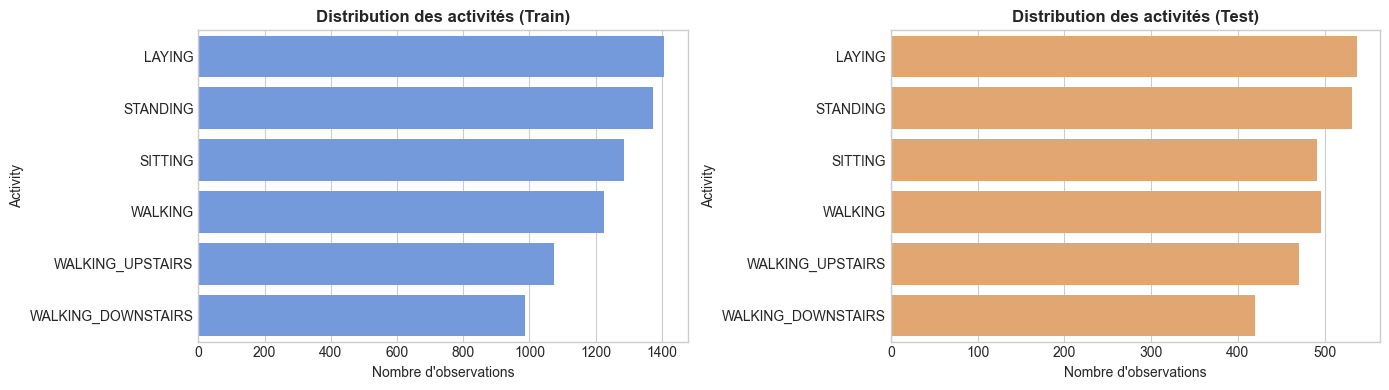

Rapport classe la plus fréquente / la moins fréquente (train) : 1.43


In [4]:
order = train_df['Activity'].value_counts().index
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=train_df, y='Activity', order=order, ax=axes[0], color='cornflowerblue')
axes[0].set_title("Distribution des activités (Train)", fontweight='bold')
axes[0].set_xlabel("Nombre d'observations")
sns.countplot(data=test_df, y='Activity', order=order, ax=axes[1], color='sandybrown')
axes[1].set_title("Distribution des activités (Test)", fontweight='bold')
axes[1].set_xlabel("Nombre d'observations")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_distribution_classes.png'), dpi=300)
plt.show()

counts = train_df['Activity'].value_counts()
print(f"Rapport classe la plus fréquente / la moins fréquente (train) : {counts.max() / counts.min():.2f}")

### Statistiques descriptives et mise à l'échelle des capteurs

In [5]:
feature_cols = [c for c in train_df.columns if c not in ['subject', 'Activity']]
features_train = train_df[feature_cols]

print(f"Nombre de variables issues des capteurs : {len(feature_cols)}")
print(f"Minimum global sur l'ensemble des variables : {features_train.min().min():.4f}")
print(f"Maximum global sur l'ensemble des variables : {features_train.max().max():.4f}")
print(f"Moyenne globale des moyennes                : {features_train.mean().mean():.4f}")
print(f"Moyenne des écarts-types                    : {features_train.std().mean():.4f}")
print(f"Nombre de valeurs manquantes (NaN)          : {train_df.isnull().sum().sum()}")
print(f"Lignes dupliquées                           : {train_df.duplicated().sum()}")

results['donnees'] = {
    'n_train': int(train_df.shape[0]), 'n_test': int(test_df.shape[0]), 'n_features': len(feature_cols),
    'n_subjects_train': len(train_subjects), 'n_subjects_test': len(test_subjects),
    'min_global': float(features_train.min().min()), 'max_global': float(features_train.max().max()),
    'ratio_classes': float(counts.max() / counts.min()),
}

Nombre de variables issues des capteurs : 561
Minimum global sur l'ensemble des variables : -1.0000
Maximum global sur l'ensemble des variables : 1.0000
Moyenne globale des moyennes                : -0.5084
Moyenne des écarts-types                    : 0.2837
Nombre de valeurs manquantes (NaN)          : 0


Lignes dupliquées                           : 0


### Questions de prétraitement :
1. **Les variables sont-elles déjà mises à l'échelle ?**
   Oui : toutes les variables sont comprises dans $[-1, 1]$ (normalisation faite par les auteurs du jeu de données).
   Leurs ordres de grandeur sont donc comparables ; nous n'ajoutons pas de standardisation, ce qui évite aussi de devoir
   calculer des statistiques de normalisation (qui devraient l'être sur l'apprentissage uniquement).
2. **La colonne `subject` doit-elle servir d'entrée au modèle ?**
   Non. `subject` est un identifiant de personne, pas une mesure physique, et les volontaires du test sont absents de
   l'apprentissage : le modèle ne pourrait rien en tirer pour de nouvelles personnes. Elle sert en revanche à construire
   la validation (section 3).
3. **Encodage de la cible :** les activités sont encodées en entiers de 0 à 5 (`LabelEncoder`), le format attendu par
   `CrossEntropyLoss`.
4. **Classes :** la distribution est proche de l'équilibre (rapport ci-dessus) : l'accuracy reste lisible, mais nous
   suivons aussi le F1 macro, qui donne le même poids à chaque classe.

## 3. Découpage et Ensemble de Validation (Partie 1.3)

Tous nos choix sont guidés par un ensemble de validation extrait de `train.csv`.

**Problématique :** doit-on découper les lignes au hasard ou réserver des volontaires entiers ?
- Les mesures sont découpées en fenêtres de 2,56 s avec **50 % de chevauchement** : deux fenêtres consécutives d'un
  même individu sont presque identiques.
- Un découpage aléatoire placerait des fenêtres quasi jumelles en apprentissage et en validation : c'est une **fuite
  d'information**, et le score de validation serait trop optimiste. Or le test contient des personnes nouvelles.

On compare les deux découpages avec le même modèle (la régression logistique). La comparaison avec le test est faite
en section 8, une fois tous les choix figés.

In [6]:
le = LabelEncoder()
y_train_full = le.fit_transform(train_df['Activity'])
X_train_full = train_df[feature_cols].values.astype(np.float32)
CLASSES = list(le.classes_)

# 1. Découpage aléatoire (80 % / 20 %)
X_tr_rand, X_val_rand, y_tr_rand, y_val_rand = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full)
lr_rand = LogisticRegression(max_iter=1000, random_state=42)
lr_rand.fit(X_tr_rand, y_tr_rand)
acc_val_rand = accuracy_score(y_val_rand, lr_rand.predict(X_val_rand))

# 2. Découpage par volontaires (sujets 1, 3, 5, 7 en validation)
val_subjects = [1, 3, 5, 7]
mask_val = train_df['subject'].isin(val_subjects)
X_tr_subj = train_df[~mask_val][feature_cols].values.astype(np.float32)
y_tr_subj = le.transform(train_df[~mask_val]['Activity'])
X_val_subj = train_df[mask_val][feature_cols].values.astype(np.float32)
y_val_subj = le.transform(train_df[mask_val]['Activity'])

print(f"Découpage aléatoire       : {len(y_tr_rand)} apprentissage / {len(y_val_rand)} validation")
print(f"Découpage par volontaires : {len(y_tr_subj)} apprentissage / {len(y_val_subj)} validation "
      f"({mask_val.mean():.1%} des fenêtres)")

Découpage aléatoire       : 5881 apprentissage / 1471 validation
Découpage par volontaires : 6054 apprentissage / 1298 validation (17.7% des fenêtres)


### Référence : régression logistique multiclasse (Partie 1.4)
C'est un réseau sans couche cachée (couche linéaire $561 \to 6$ + softmax) : tous les MLP lui seront comparés.

In [7]:
lr_subj = LogisticRegression(max_iter=1000, random_state=42)
lr_subj.fit(X_tr_subj, y_tr_subj)
pred_val_lr = lr_subj.predict(X_val_subj)
acc_val_subj = accuracy_score(y_val_subj, pred_val_lr)
f1_val_subj = f1_score(y_val_subj, pred_val_lr, average='macro')

print("=" * 60)
print(f"Découpage aléatoire       : Val Acc = {acc_val_rand*100:.2f}%")
print(f"Découpage par volontaires : Val Acc = {acc_val_subj*100:.2f}% | Val F1 macro = {f1_val_subj*100:.2f}%")
print("=" * 60)
print("F1 par classe (référence, validation par volontaires) :")
print(pd.Series(f1_score(y_val_subj, pred_val_lr, average=None), index=CLASSES).round(3).to_string())

results['reference'] = {'val_acc': acc_val_subj, 'val_f1': f1_val_subj,
                        'f1_par_classe_val': dict(zip(CLASSES, f1_score(y_val_subj, pred_val_lr, average=None).tolist()))}
results['decoupage'] = {'val_acc_aleatoire': acc_val_rand, 'val_acc_volontaires': acc_val_subj}

Découpage aléatoire       : Val Acc = 98.57%
Découpage par volontaires : Val Acc = 95.99% | Val F1 macro = 95.81%
F1 par classe (référence, validation par volontaires) :
LAYING                1.000
SITTING               0.892
STANDING              0.899
WALKING               0.994
WALKING_DOWNSTAIRS    0.987
WALKING_UPSTAIRS      0.976


**Lecture :** le découpage aléatoire donne un meilleur score de validation. Ce n'est pas le signe d'un meilleur
modèle (c'est le même), mais celui d'une évaluation plus facile : des fenêtres quasi identiques sont des deux côtés.
La section 8 dira lequel des deux scores est le plus proche de la performance réelle sur des personnes nouvelles.

### Préparation des DataLoaders PyTorch (découpage par volontaire)

In [8]:
batch_size = 64
train_dataset = TensorDataset(torch.tensor(X_tr_subj), torch.tensor(y_tr_subj))
val_dataset = TensorDataset(torch.tensor(X_val_subj), torch.tensor(y_val_subj))
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f"Taille Train : {len(train_dataset)} échantillons ({len(train_loader)} batches)")
print(f"Taille Val   : {len(val_dataset)} échantillons ({len(val_loader)} batches)")

Taille Train : 6054 échantillons (95 batches)
Taille Val   : 1298 échantillons (21 batches)


## 4. Définition du Modèle & Sanity Checks (Partie 2.1)

Réseau à **une seule couche cachée** : entrée 561 → 64 neurones → 6 logits (pas de softmax dans le modèle :
`nn.CrossEntropyLoss` l'applique elle-même).

In [9]:
class SimpleMLP(nn.Module):
    def __init__(self, input_dim=561, hidden_dim=64, num_classes=6, activation='relu'):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        if activation == 'relu':
            self.act = nn.ReLU()
        elif activation == 'sigmoid':
            self.act = nn.Sigmoid()
        elif activation == 'tanh':
            self.act = nn.Tanh()
        else:
            raise ValueError(f"Activation inconnue: {activation}")
        self.fc2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.fc1(x)
        x = self.act(x)
        x = self.fc2(x)
        return x

set_seed(42)
model_check = SimpleMLP(hidden_dim=64, activation='relu')
print(model_check)
n_params = sum(p.numel() for p in model_check.parameters())
print(f"Nombre de paramètres : {n_params} (= 561×64 + 64 + 64×6 + 6)")

SimpleMLP(
  (fc1): Linear(in_features=561, out_features=64, bias=True)
  (act): ReLU()
  (fc2): Linear(in_features=64, out_features=6, bias=True)
)
Nombre de paramètres : 36358 (= 561×64 + 64 + 64×6 + 6)


### Vérification 1 : Perte initiale théorique
À l'initialisation, les logits sont proches de zéro : la probabilité prédite pour chaque classe vaut environ $1/6$,
et la perte attendue est
$$\mathcal{L}_0 = -\ln\left(\frac{1}{6}\right) = \ln(6) \approx 1{,}7918$$

In [10]:
criterion = nn.CrossEntropyLoss()
init_losses = []
for s in [42, 123, 999]:
    set_seed(s)
    m = SimpleMLP(hidden_dim=64, activation='relu')
    m.eval()
    with torch.no_grad():
        init_losses.append(criterion(m(torch.tensor(X_val_subj)), torch.tensor(y_val_subj)).item())

print(f"Perte initiale (validation, 3 graines) : {np.mean(init_losses):.4f} ± {np.std(init_losses, ddof=1):.4f}")
print(f"Perte théorique ln(6)                  : {np.log(6):.4f}")
results['perte_initiale'] = {'moyenne': float(np.mean(init_losses)), 'theorique': float(np.log(6))}

Perte initiale (validation, 3 graines) : 1.7968 ± 0.0196
Perte théorique ln(6)                  : 1.7918


### Vérification 2 : Capacité à surapprendre un petit lot (*Sanity Check*)
On entraîne le réseau sur 10 exemples seulement : la perte doit tendre vers 0 et la précision atteindre 100 %. Sinon,
il y a un bogue (données, perte, optimiseur).

In [11]:
set_seed(42)
xb, yb = next(iter(train_loader))
x_tiny, y_tiny = xb[:10], yb[:10]

overfit_model = SimpleMLP(hidden_dim=64, activation='relu')
optimizer_tiny = optim.Adam(overfit_model.parameters(), lr=0.01)
N_ITER_TINY = 100
losses_tiny = []
for it in range(N_ITER_TINY):
    optimizer_tiny.zero_grad()
    loss = criterion(overfit_model(x_tiny), y_tiny)
    loss.backward()
    optimizer_tiny.step()
    losses_tiny.append(loss.item())

acc_tiny = (overfit_model(x_tiny).argmax(dim=1) == y_tiny).float().mean().item()
print(f"Perte sur le mini-lot : {losses_tiny[0]:.4f} -> {losses_tiny[-1]:.6f} ({N_ITER_TINY} itérations)")
print(f"Précision sur le mini-lot : {acc_tiny * 100:.1f}%")
results['sanity_check'] = {'perte_finale': losses_tiny[-1], 'precision': acc_tiny, 'iterations': N_ITER_TINY}

Perte sur le mini-lot : 1.7272 -> 0.000999 (100 itérations)
Précision sur le mini-lot : 100.0%


## 5. Fonctions d'Entraînement et d'Évaluation

In [12]:
def train_epoch(model, dataloader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x_batch, y_batch in dataloader:
        optimizer.zero_grad()
        outputs = model(x_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x_batch.size(0)
        correct += (outputs.argmax(dim=1) == y_batch).sum().item()
        total += x_batch.size(0)
    return total_loss / total, correct / total

def evaluate(model, dataloader, criterion):
    model.eval()
    total_loss, all_preds, all_targets = 0.0, [], []
    with torch.no_grad():
        for x_batch, y_batch in dataloader:
            outputs = model(x_batch)
            total_loss += criterion(outputs, y_batch).item() * x_batch.size(0)
            all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())
    total = len(all_targets)
    return (total_loss / total, accuracy_score(all_targets, all_preds),
            f1_score(all_targets, all_preds, average='macro'), all_preds, all_targets)

def run_experiment(activation='relu', opt_name='adam', lr=0.001, epochs=EPOCHS, seed=42):
    set_seed(seed)
    model = SimpleMLP(hidden_dim=64, activation=activation)
    criterion = nn.CrossEntropyLoss()
    if opt_name == 'sgd':
        optimizer = optim.SGD(model.parameters(), lr=lr)
    elif opt_name == 'sgd_momentum':
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif opt_name == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr)
    else:
        raise ValueError(opt_name)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_f1': []}
    for ep in range(epochs):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer)
        vl_loss, vl_acc, vl_f1, _, _ = evaluate(model, val_loader, criterion)
        for k, v in zip(history, [tr_loss, vl_loss, tr_acc, vl_acc, vl_f1]):
            history[k].append(v)
    return model, history

def mean_std(values):
    return float(np.mean(values)), float(np.std(values, ddof=1))

## 6. Essais Comparatifs : Pas d'apprentissage, Activations et Optimiseurs (Partie 2.2)

### A. Réglage du pas d'apprentissage pour chaque optimiseur
Comparer SGD et Adam avec le même pas n'aurait pas de sens : le pas est l'hyperparamètre le plus important et son bon
ordre de grandeur dépend de l'optimiseur. On entraîne donc chaque optimiseur (avec ReLU) pendant `EPOCHS_LR` époques
pour plusieurs pas d'une grille logarithmique, et l'on retient le pas qui donne le meilleur F1 macro de validation.

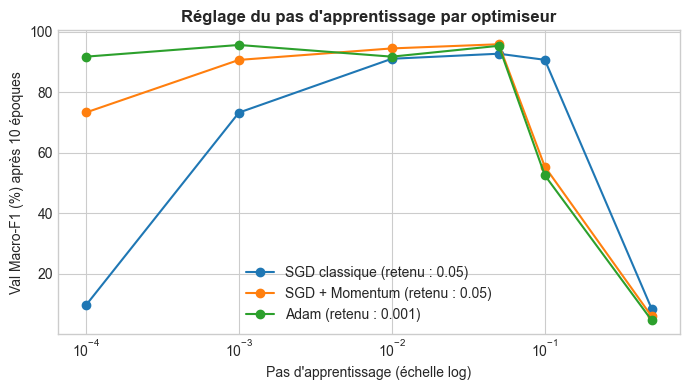

        SGD classique  SGD + Momentum   Adam
0.0001           9.66           73.34  91.78
0.0010          73.30           90.71  95.65
0.0100          91.09           94.51  91.78
0.0500          92.76           95.88  95.37
0.1000          90.74           55.45  52.59
0.5000           8.44            5.95   4.64
Pas retenus : {'sgd': 0.05, 'sgd_momentum': 0.05, 'adam': 0.001}


In [13]:
LR_GRID = [1e-4, 1e-3, 1e-2, 5e-2, 1e-1, 5e-1]
OPTIMIZERS = {'sgd': 'SGD classique', 'sgd_momentum': 'SGD + Momentum', 'adam': 'Adam'}

sweep = {}
for opt_name in OPTIMIZERS:
    sweep[opt_name] = []
    for lr in LR_GRID:
        _, h = run_experiment(activation='relu', opt_name=opt_name, lr=lr, epochs=EPOCHS_LR)
        score = h['val_f1'][-1] if np.isfinite(h['train_loss'][-1]) else 0.0
        sweep[opt_name].append(score)
best_lr = {o: LR_GRID[int(np.argmax(sweep[o]))] for o in OPTIMIZERS}

plt.figure(figsize=(7, 4))
for o, label in OPTIMIZERS.items():
    plt.semilogx(LR_GRID, np.array(sweep[o]) * 100, 'o-', label=f"{label} (retenu : {best_lr[o]:g})")
plt.xlabel("Pas d'apprentissage (échelle log)")
plt.ylabel(f"Val Macro-F1 (%) après {EPOCHS_LR} époques")
plt.title("Réglage du pas d'apprentissage par optimiseur", fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '05b_reglage_learning_rate.png'), dpi=300)
plt.show()

print(pd.DataFrame(sweep, index=LR_GRID).rename(columns=OPTIMIZERS).mul(100).round(2).to_string())
print("Pas retenus :", best_lr)
results['balayage_lr'] = {'grille': LR_GRID, 'val_f1': sweep, 'retenu': best_lr}

### B. Comparaison des fonctions d'activation (Adam, pas retenu)

RELU     : Val Loss = 0.1204 | Val Acc = 95.99% | Val F1 = 95.81%


TANH     : Val Loss = 0.1265 | Val Acc = 95.99% | Val F1 = 95.84%


SIGMOID  : Val Loss = 0.1454 | Val Acc = 94.22% | Val F1 = 94.03%


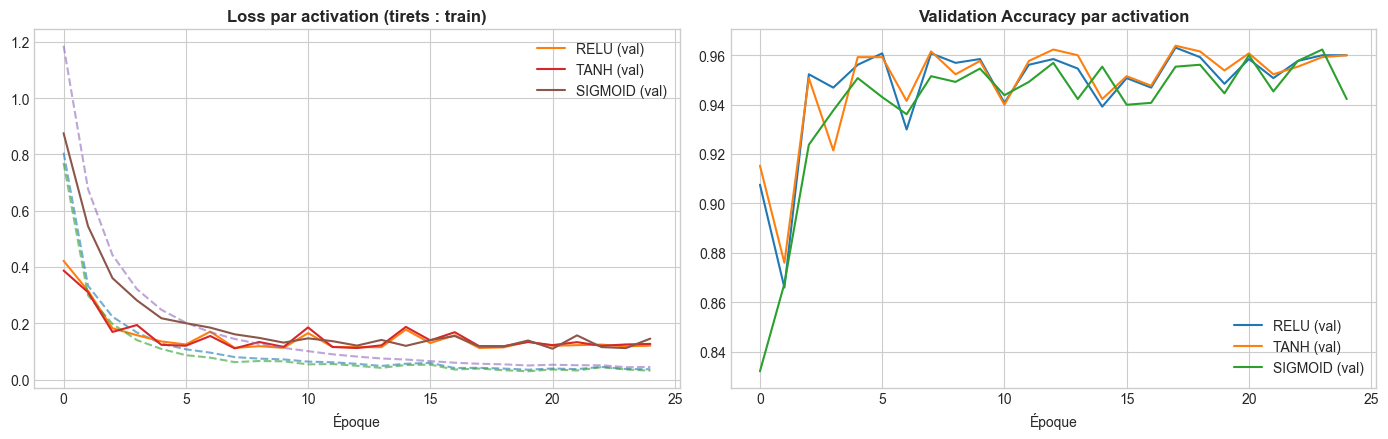

In [14]:
activations = ['relu', 'tanh', 'sigmoid']
act_histories = {}
for act in activations:
    _, hist = run_experiment(activation=act, opt_name='adam', lr=best_lr['adam'])
    act_histories[act] = hist
    print(f"{act.upper():8s} : Val Loss = {hist['val_loss'][-1]:.4f} | Val Acc = {hist['val_acc'][-1]*100:.2f}% "
          f"| Val F1 = {hist['val_f1'][-1]*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for act in activations:
    axes[0].plot(act_histories[act]['train_loss'], ls='--', alpha=0.6)
    axes[0].plot(act_histories[act]['val_loss'], label=f"{act.upper()} (val)")
    axes[1].plot(act_histories[act]['val_acc'], label=f"{act.upper()} (val)")
axes[0].set_title("Loss par activation (tirets : train)", fontweight='bold')
axes[0].set_xlabel("Époque"); axes[0].legend()
axes[1].set_title("Validation Accuracy par activation", fontweight='bold')
axes[1].set_xlabel("Époque"); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '05_comparaison_activations.png'), dpi=300)
plt.show()

### C. Comparaison des optimiseurs (ReLU, chacun avec son pas retenu)

SGD classique   (lr=0.05) : Val Loss = 0.1129 | Val Acc = 95.92% | Val F1 = 95.72%


SGD + Momentum  (lr=0.05) : Val Loss = 0.1929 | Val Acc = 92.45% | Val F1 = 92.11%


Adam            (lr=0.001) : Val Loss = 0.1204 | Val Acc = 95.99% | Val F1 = 95.81%


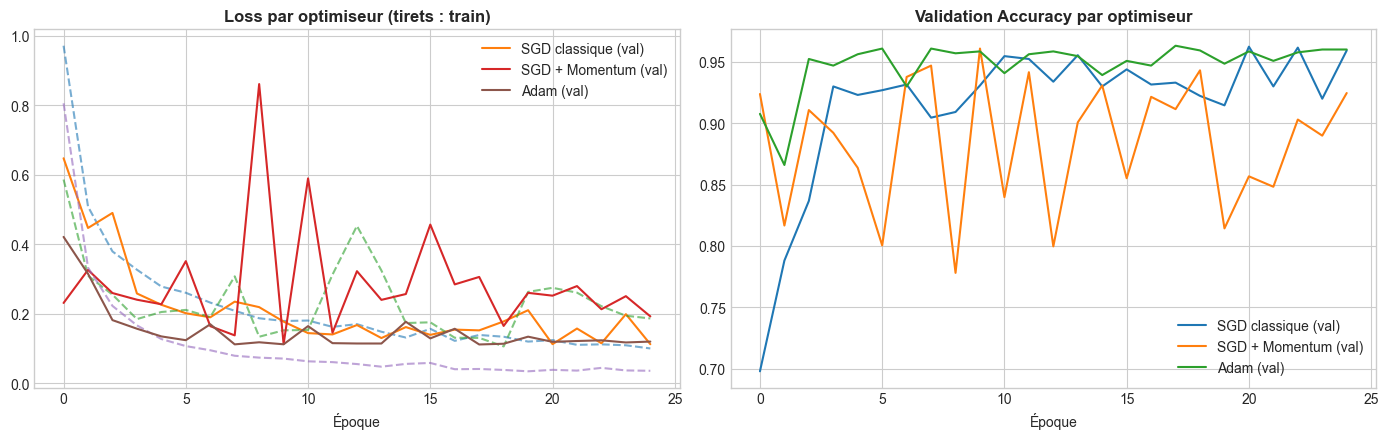

In [15]:
opt_histories = {}
for opt_name, label in OPTIMIZERS.items():
    _, hist = run_experiment(activation='relu', opt_name=opt_name, lr=best_lr[opt_name])
    opt_histories[opt_name] = hist
    print(f"{label:15s} (lr={best_lr[opt_name]:g}) : Val Loss = {hist['val_loss'][-1]:.4f} "
          f"| Val Acc = {hist['val_acc'][-1]*100:.2f}% | Val F1 = {hist['val_f1'][-1]*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for opt_name, label in OPTIMIZERS.items():
    axes[0].plot(opt_histories[opt_name]['train_loss'], ls='--', alpha=0.6)
    axes[0].plot(opt_histories[opt_name]['val_loss'], label=f"{label} (val)")
    axes[1].plot(opt_histories[opt_name]['val_acc'], label=f"{label} (val)")
axes[0].set_title("Loss par optimiseur (tirets : train)", fontweight='bold')
axes[0].set_xlabel("Époque"); axes[0].legend()
axes[1].set_title("Validation Accuracy par optimiseur", fontweight='bold')
axes[1].set_xlabel("Époque"); axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '06_comparaison_optimiseurs.png'), dpi=300)
plt.show()

results['activations'] = {a: {'val_loss': h['val_loss'][-1], 'val_acc': h['val_acc'][-1], 'val_f1': h['val_f1'][-1],
                              'train_loss': h['train_loss'][-1]} for a, h in act_histories.items()}
results['optimiseurs'] = {o: {'lr': best_lr[o], 'val_loss': h['val_loss'][-1], 'val_acc': h['val_acc'][-1],
                              'val_f1': h['val_f1'][-1], 'train_loss': h['train_loss'][-1]} for o, h in opt_histories.items()}

**Lecture des courbes :** on compare la vitesse de convergence (SGD simple est le plus lent), la stabilité des courbes
de validation, et l'écart entre la perte d'apprentissage (tirets) et celle de validation, qui signale le
surapprentissage quand il se creuse.

## 7. Variabilité des Résultats et Analyse Multi-Graines (Partie 2.3)

Un écart entre deux configurations plus petit que la variabilité due à la graine ne permet pas de conclure. On répète
donc l'entraînement sur **3 graines** (42, 123, 999) pour trois configurations, et l'on applique une règle simple :
l'écart est jugé significatif si $|\bar{x}_1-\bar{x}_2| > s_1 + s_2$ ($s$ : écart-type sur les 3 graines).

In [16]:
seeds = [42, 123, 999]
configs_seeds = {
    'ReLU + Adam': ('relu', 'adam'),
    'Tanh + Adam': ('tanh', 'adam'),
    'ReLU + SGD Momentum': ('relu', 'sgd_momentum'),
}
seed_scores, seed_models = {}, {}
for name, (act, opt_name) in configs_seeds.items():
    accs, f1s, mods = [], [], []
    for s in seeds:
        m, h = run_experiment(activation=act, opt_name=opt_name, lr=best_lr[opt_name], seed=s)
        accs.append(h['val_acc'][-1]); f1s.append(h['val_f1'][-1]); mods.append(m)
    seed_scores[name] = {'acc': accs, 'f1': f1s}
    seed_models[name] = mods

print("=" * 72)
for name, sc in seed_scores.items():
    ma, sa = mean_std(sc['acc']); mf, sf = mean_std(sc['f1'])
    print(f"{name:20s} : Val Acc = {ma*100:.2f}% ± {sa*100:.2f} | Val F1 = {mf*100:.2f}% ± {sf*100:.2f}")
print("=" * 72)

names = sorted(seed_scores, key=lambda n: -np.mean(seed_scores[n]['f1']))
best_name = names[0]
for other in names[1:]:
    (m1, s1), (m2, s2) = mean_std(seed_scores[best_name]['f1']), mean_std(seed_scores[other]['f1'])
    verdict = "significatif" if m1 - m2 > s1 + s2 else "non significatif (on ne peut pas conclure)"
    print(f"{best_name} vs {other} : écart de F1 = {(m1-m2)*100:.2f} pt, s1+s2 = {(s1+s2)*100:.2f} pt -> {verdict}")
m1, s1 = mean_std(seed_scores[best_name]['f1'])
print(f"{best_name} vs référence : écart de F1 = {(m1 - f1_val_subj)*100:.2f} pt (s = {s1*100:.2f} pt)")

retenue = {'nom': best_name, 'activation': configs_seeds[best_name][0], 'optimiseur': configs_seeds[best_name][1],
           'lr': best_lr[configs_seeds[best_name][1]], 'epochs': EPOCHS}
print("Configuration V1 retenue :", retenue)
results['graines'] = {n: {'val_acc': mean_std(sc['acc']), 'val_f1': mean_std(sc['f1'])} for n, sc in seed_scores.items()}
results['v1_retenue'] = retenue

ReLU + Adam          : Val Acc = 95.35% ± 0.86 | Val F1 = 95.08% ± 1.02
Tanh + Adam          : Val Acc = 95.43% ± 0.54 | Val F1 = 95.22% ± 0.62
ReLU + SGD Momentum  : Val Acc = 94.50% ± 1.78 | Val F1 = 94.29% ± 1.89
Tanh + Adam vs ReLU + Adam : écart de F1 = 0.14 pt, s1+s2 = 1.64 pt -> non significatif (on ne peut pas conclure)
Tanh + Adam vs ReLU + SGD Momentum : écart de F1 = 0.93 pt, s1+s2 = 2.51 pt -> non significatif (on ne peut pas conclure)
Tanh + Adam vs référence : écart de F1 = -0.60 pt (s = 0.62 pt)
Configuration V1 retenue : {'nom': 'Tanh + Adam', 'activation': 'tanh', 'optimiseur': 'adam', 'lr': 0.001, 'epochs': 25}


**Accuracy ou F1 ?** Les classes étant proches de l'équilibre, l'accuracy et le F1 macro sont très proches et classent
les configurations de la même façon. Le F1 par classe (section 8) reste le plus utile pour voir *quelles* activités
sont mal reconnues.

## 8. Évaluation finale sur le jeu de test (passage unique)

Tous les choix sont figés. On évalue **une seule fois** sur `test.csv` (9 volontaires jamais vus) :
- la référence (régression logistique) ;
- le MLP retenu, pour ses 3 graines (moyenne ± écart-type) ;
- pour conclure la partie 1.3 : la régression logistique entraînée avec le découpage aléatoire.

In [17]:
y_test = le.transform(test_df['Activity'])
X_test = test_df[feature_cols].values.astype(np.float32)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test), torch.tensor(y_test)), batch_size=batch_size, shuffle=False)

pred_test_lr = lr_subj.predict(X_test)
acc_test_lr, f1_test_lr = accuracy_score(y_test, pred_test_lr), f1_score(y_test, pred_test_lr, average='macro')
acc_test_rand = accuracy_score(y_test, lr_rand.predict(X_test))

mlp_test = [evaluate(m, test_loader, criterion) for m in seed_models[best_name]]
acc_mlp = mean_std([r[1] for r in mlp_test]); f1_mlp = mean_std([r[2] for r in mlp_test])
acc_val_mlp = mean_std(seed_scores[best_name]['acc'])

print("=" * 78)
print(f"{'Modèle':32s} | {'Val Acc':>15s} | {'Test Acc':>15s} | {'Test F1':>15s}")
print("-" * 78)
print(f"{'Régression logistique':32s} | {acc_val_subj*100:14.2f}% | {acc_test_lr*100:14.2f}% | {f1_test_lr*100:14.2f}%")
print(f"{'MLP 1 couche (' + best_name + ')':32s} | {acc_val_mlp[0]*100:6.2f}% ± {acc_val_mlp[1]*100:.2f} "
      f"| {acc_mlp[0]*100:6.2f}% ± {acc_mlp[1]*100:.2f} | {f1_mlp[0]*100:6.2f}% ± {f1_mlp[1]*100:.2f}")
print("=" * 78)
print("Partie 1.3 — régression logistique :")
print(f"  découpage aléatoire       : Val {acc_val_rand*100:.2f}% | Test {acc_test_rand*100:.2f}% | écart {(acc_val_rand-acc_test_rand)*100:+.2f} pt")
print(f"  découpage par volontaires : Val {acc_val_subj*100:.2f}% | Test {acc_test_lr*100:.2f}% | écart {(acc_val_subj-acc_test_lr)*100:+.2f} pt")

Modèle                           |         Val Acc |        Test Acc |         Test F1
------------------------------------------------------------------------------
Régression logistique            |          95.99% |          95.28% |          95.28%
MLP 1 couche (Tanh + Adam)       |  95.43% ± 0.54 |  93.88% ± 1.30 |  93.91% ± 1.33
Partie 1.3 — régression logistique :
  découpage aléatoire       : Val 98.57% | Test 96.13% | écart +2.44 pt
  découpage par volontaires : Val 95.99% | Test 95.28% | écart +0.71 pt


Rapport par classe — MLP retenu (graine 42) :
                    precision    recall  f1-score   support

            LAYING      1.000     0.974     0.987       537
           SITTING      0.934     0.859     0.895       491
          STANDING      0.861     0.944     0.900       532
           WALKING      0.944     0.992     0.968       496
WALKING_DOWNSTAIRS      0.988     0.952     0.970       420
  WALKING_UPSTAIRS      0.957     0.941     0.949       471

          accuracy                          0.944      2947
         macro avg      0.947     0.944     0.945      2947
      weighted avg      0.946     0.944     0.944      2947



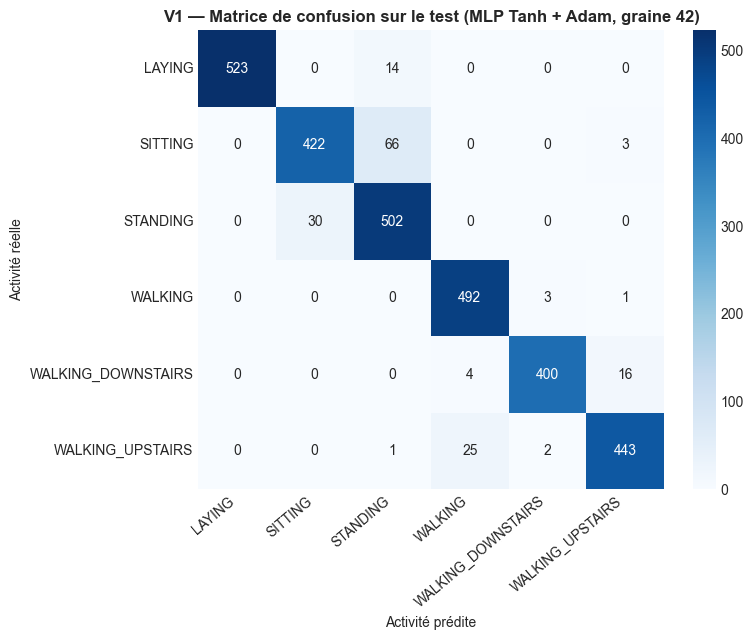

Résultats enregistrés dans reports/results/v1_results.json


In [18]:
_, _, _, preds_mlp, targets_mlp = mlp_test[0]
print("Rapport par classe — MLP retenu (graine 42) :")
print(classification_report(targets_mlp, preds_mlp, target_names=CLASSES, digits=3))

cm = confusion_matrix(targets_mlp, preds_mlp)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title(f"V1 — Matrice de confusion sur le test (MLP {best_name}, graine 42)", fontweight='bold')
plt.xlabel("Activité prédite"); plt.ylabel("Activité réelle")
plt.xticks(rotation=40, ha='right'); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'v1_matrice_confusion_test.png'), dpi=300)
plt.show()

results['test'] = {
    'reference': {'acc': acc_test_lr, 'f1': f1_test_lr,
                  'f1_par_classe': dict(zip(CLASSES, f1_score(y_test, pred_test_lr, average=None).tolist()))},
    'mlp_v1': {'acc': acc_mlp, 'f1': f1_mlp, 'val_acc': acc_val_mlp,
               'f1_par_classe': dict(zip(CLASSES, f1_score(targets_mlp, preds_mlp, average=None).tolist())),
               'confusion': cm.tolist()},
    'decoupage': {'aleatoire': {'val': acc_val_rand, 'test': acc_test_rand},
                  'volontaires': {'val': acc_val_subj, 'test': acc_test_lr}},
}
with open(os.path.join(RES_DIR, 'v1_results.json'), 'w') as f:
    json.dump(results, f, indent=2, default=float)
print("Résultats enregistrés dans reports/results/v1_results.json")

### Conclusions de la Version 1
- **Partie 1.3 :** comparer l'écart validation − test des deux découpages ; le découpage par volontaires doit donner
  l'estimation la plus fidèle, car le test contient des personnes nouvelles.
- **MLP vs référence :** comparer leurs scores de test au regard de l'écart-type du MLP ; si la régression logistique
  fait aussi bien ou mieux, c'est que les 561 variables, déjà très élaborées, rendent le problème presque linéairement
  séparable : la couche cachée apporte alors peu.
- **Confusions :** la matrice de confusion montre quelles activités sont confondues ; SITTING / STANDING (deux
  postures immobiles où le téléphone mesure surtout la gravité, d'orientation proche) est la confusion attendue.